In [ ]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import xgboost as xgb
import shap


## Data Cleaning

In [2]:
df_raw = pd.read_csv("ames.csv")
df = df_raw.drop(columns=["Order", "PID"], errors="ignore")
df = df[df["Gr Liv Area"] <= 4000].reset_index(drop=True)

y_actual = df["SalePrice"].copy()
y_log = np.log1p(y_actual)
X_raw = df.drop(columns=["SalePrice"]).copy()

print(f"Dataset Shape: {df.shape}")
print(f"Features: {X_raw.shape[1]}")

Dataset Shape: (2925, 80)
Features: 79


## Feature Engineering

In [3]:
def add_engineered_features(data):
    d = data.copy()
    
    d["TotalSF"] = d["Total Bsmt SF"].fillna(0) + d["1st Flr SF"] + d["2nd Flr SF"]
    d["TotalLivingSF"] = d["Gr Liv Area"] + d["BsmtFin SF 1"].fillna(0) + d["BsmtFin SF 2"].fillna(0)
    d["TotalPorchSF"] = (
        d["Wood Deck SF"].fillna(0) + d["Open Porch SF"].fillna(0) +
        d["Enclosed Porch"].fillna(0) + d["3Ssn Porch"].fillna(0) + d["Screen Porch"].fillna(0)
    )
    d["AboveGroundRatio"] = d["Gr Liv Area"] / (d["TotalSF"] + 1)
    d["LotToLivingRatio"] = d["Lot Area"] / (d["Gr Liv Area"] + 1)
    
    d["HouseAge"] = (d["Yr Sold"] - d["Year Built"]).clip(lower=0)
    d["YearsSinceRemod"] = (d["Yr Sold"] - d["Year Remod/Add"]).clip(lower=0)
    d["IsRemodeled"] = (d["Year Remod/Add"] != d["Year Built"]).astype(int)
    d["IsNewHouse"] = (d["Yr Sold"] == d["Year Built"]).astype(int)
    
    d["TotalBath"] = (
        d["Full Bath"].fillna(0) + 0.5 * d["Half Bath"].fillna(0) +
        d["Bsmt Full Bath"].fillna(0) + 0.5 * d["Bsmt Half Bath"].fillna(0)
    )
    d["LivingAreaPerRoom"] = d["Gr Liv Area"] / (d["TotRms AbvGrd"] + 1)
    d["BedBathRatio"] = d["Bedroom AbvGr"] / (d["TotalBath"] + 0.5)
    
    qual_map = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}
    exposure_map = {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "None": 0}
    fin_type_map = {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0}
    finish_map = {"Fin": 3, "RFn": 2, "Unf": 1, "None": 0}
    functional_map = {"Typ": 7, "Min1": 6, "Min2": 5, "Mod": 4, "Maj1": 3, "Maj2": 2, "Sev": 1, "Sal": 0}
    paved_map = {"Y": 2, "P": 1, "N": 0}

    d["ExterQualNum"] = d["Exter Qual"].map(qual_map).fillna(3)
    d["ExterCondNum"] = d["Exter Cond"].map(qual_map).fillna(3)
    d["BsmtQualNum"] = d["Bsmt Qual"].map(qual_map).fillna(0)
    d["BsmtCondNum"] = d["Bsmt Cond"].map(qual_map).fillna(0)
    d["KitchenQualNum"] = d["Kitchen Qual"].map(qual_map).fillna(3)
    d["FireplaceQuNum"] = d["Fireplace Qu"].map(qual_map).fillna(0)
    d["GarageQualNum"] = d["Garage Qual"].map(qual_map).fillna(0)
    d["HeatingQCNum"] = d["Heating QC"].map(qual_map).fillna(3)

    d["OverallGradeIndex"] = d["Overall Qual"] * d["Overall Cond"]
    d["ExterIndex"] = d["ExterQualNum"] * d["ExterCondNum"]
    d["BsmtExposureNum"] = d["Bsmt Exposure"].map(exposure_map).fillna(0)
    d["BsmtFinType1Num"] = d["BsmtFin Type 1"].map(fin_type_map).fillna(0)
    d["GarageFinishNum"] = d["Garage Finish"].map(finish_map).fillna(0)
    d["FunctionalNum"] = d["Functional"].map(functional_map).fillna(7)
    d["PavedDriveNum"] = d["Paved Drive"].map(paved_map).fillna(2)
    d["HasCentralAir"] = (d["Central Air"] == "Y").astype(int)

    d["LuxuryFeatureScore"] = (
        (d["Pool Area"].fillna(0) > 0).astype(int) +
        (d["Fireplaces"].fillna(0) > 0).astype(int) +
        d["HasCentralAir"] +
        (d["BsmtFin SF 1"].fillna(0) > 0).astype(int) +
        (d["Garage Cars"].fillna(0) >= 2).astype(int)
    )

    if "Lot Frontage" in d.columns:
        d["Lot Frontage"] = d.groupby("Neighborhood")["Lot Frontage"].transform(
            lambda s: s.fillna(s.median())
        )
        d["Lot Frontage"] = d["Lot Frontage"].fillna(d["Lot Frontage"].median())

    return d

X_feat = add_engineered_features(X_raw)

## Scikit-Learn Pipeline


In [4]:
num_features = X_feat.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_feat.select_dtypes(include=["object"]).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_features),
        ("cat", cat_pipeline, cat_features)
    ]
)

## Exploratory Data Analysis

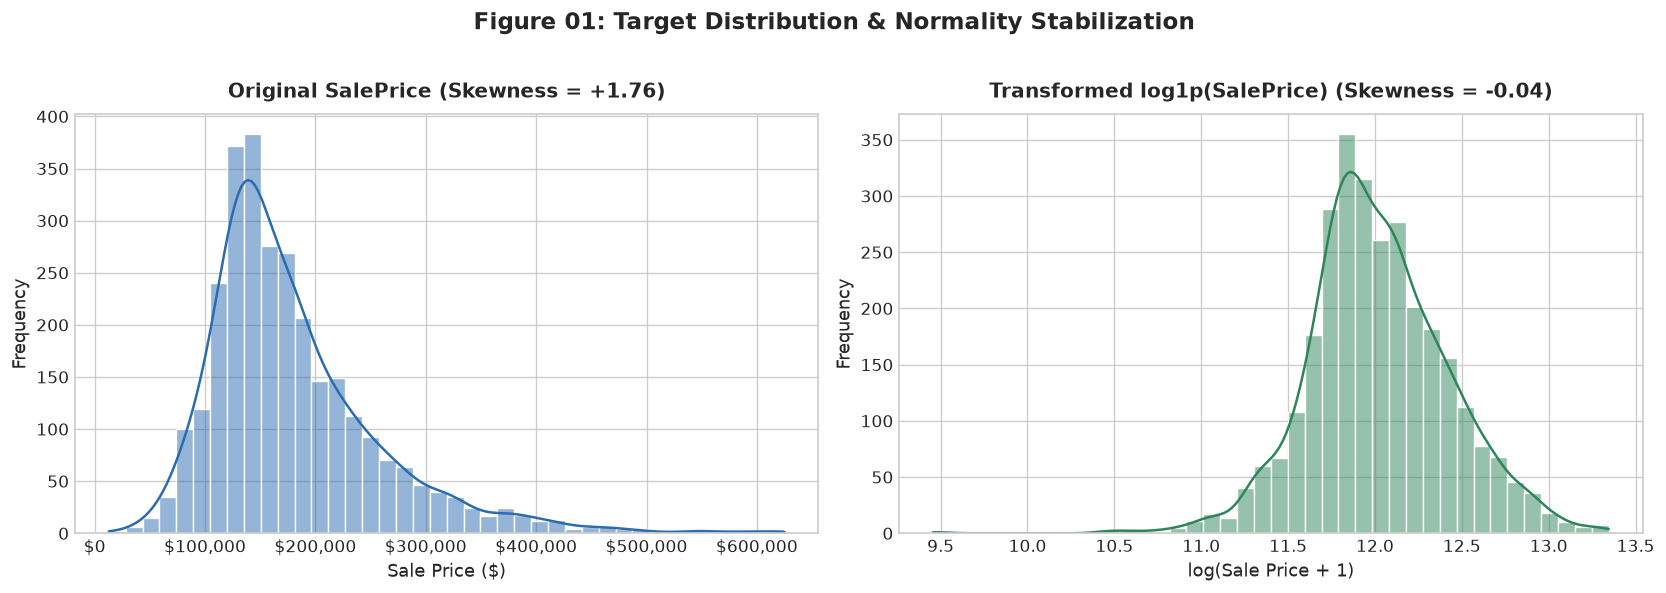

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(y_actual, kde=True, ax=axes[0], color="#2b6cb0", edgecolor="white", bins=40)
axes[0].set_title("Original SalePrice (Skewness = +1.76)", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Sale Price ($)", fontsize=10.5)
axes[0].set_ylabel("Frequency", fontsize=10.5)
axes[0].xaxis.set_major_formatter("${x:,.0f}")

sns.histplot(y_log, kde=True, ax=axes[1], color="#2f855a", edgecolor="white", bins=40)
axes[1].set_title("Transformed log1p(SalePrice) (Skewness = -0.04)", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("log(Sale Price + 1)", fontsize=10.5)
axes[1].set_ylabel("Frequency", fontsize=10.5)

plt.suptitle("Figure 01: Target Distribution & Normality Stabilization", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

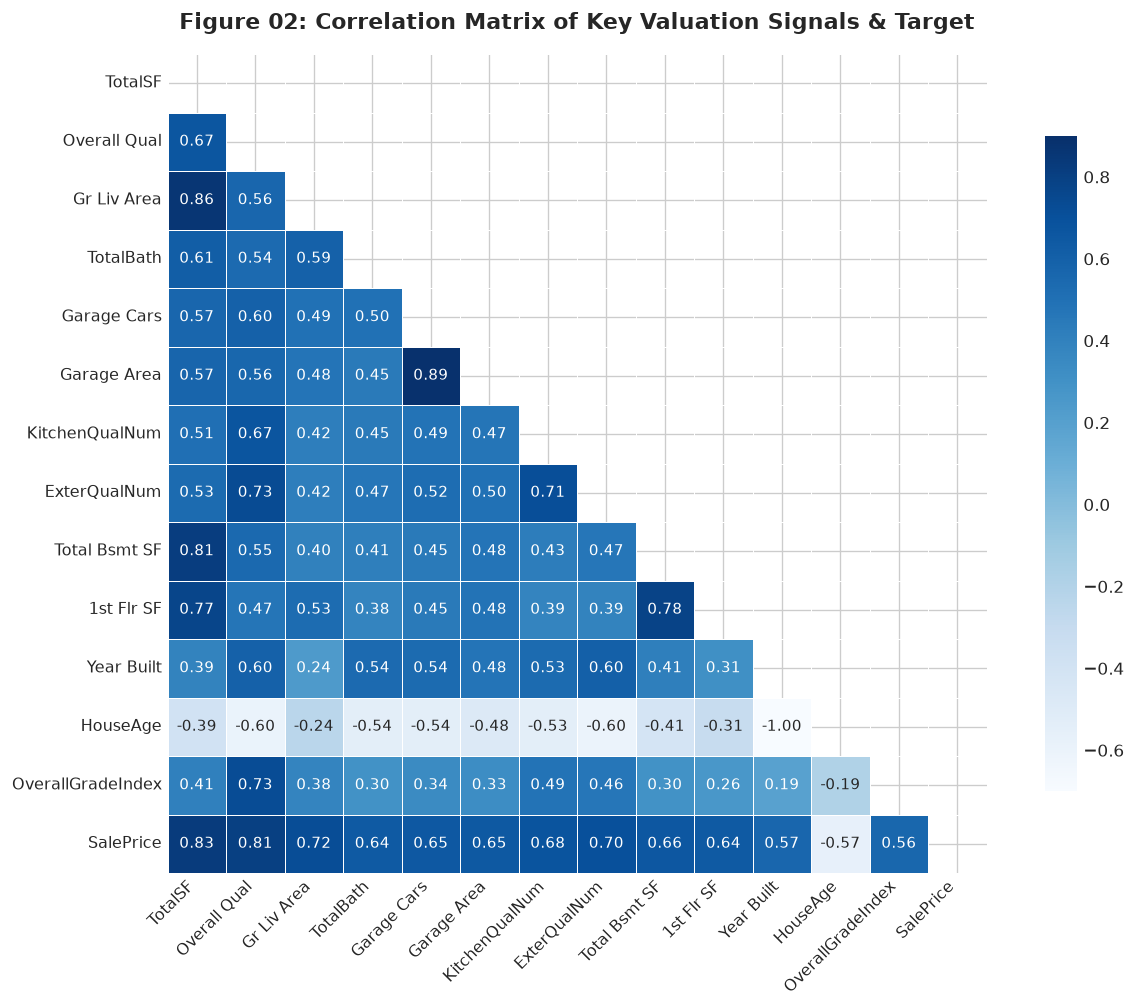

In [6]:
corr_df = X_feat[
    ["TotalSF", "Overall Qual", "Gr Liv Area", "TotalBath", "Garage Cars",
     "Garage Area", "KitchenQualNum", "ExterQualNum", "Total Bsmt SF", "1st Flr SF",
     "Year Built", "HouseAge", "OverallGradeIndex"]
].copy()
corr_df["SalePrice"] = y_actual
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap="Blues", vmax=0.9, vmin=-0.7, annot=True, fmt=".2f",
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot_kws={"size": 9}, ax=ax)
ax.set_title("Figure 02: Correlation Matrix of Key Valuation Signals & Target", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)
plt.tight_layout()
plt.show()

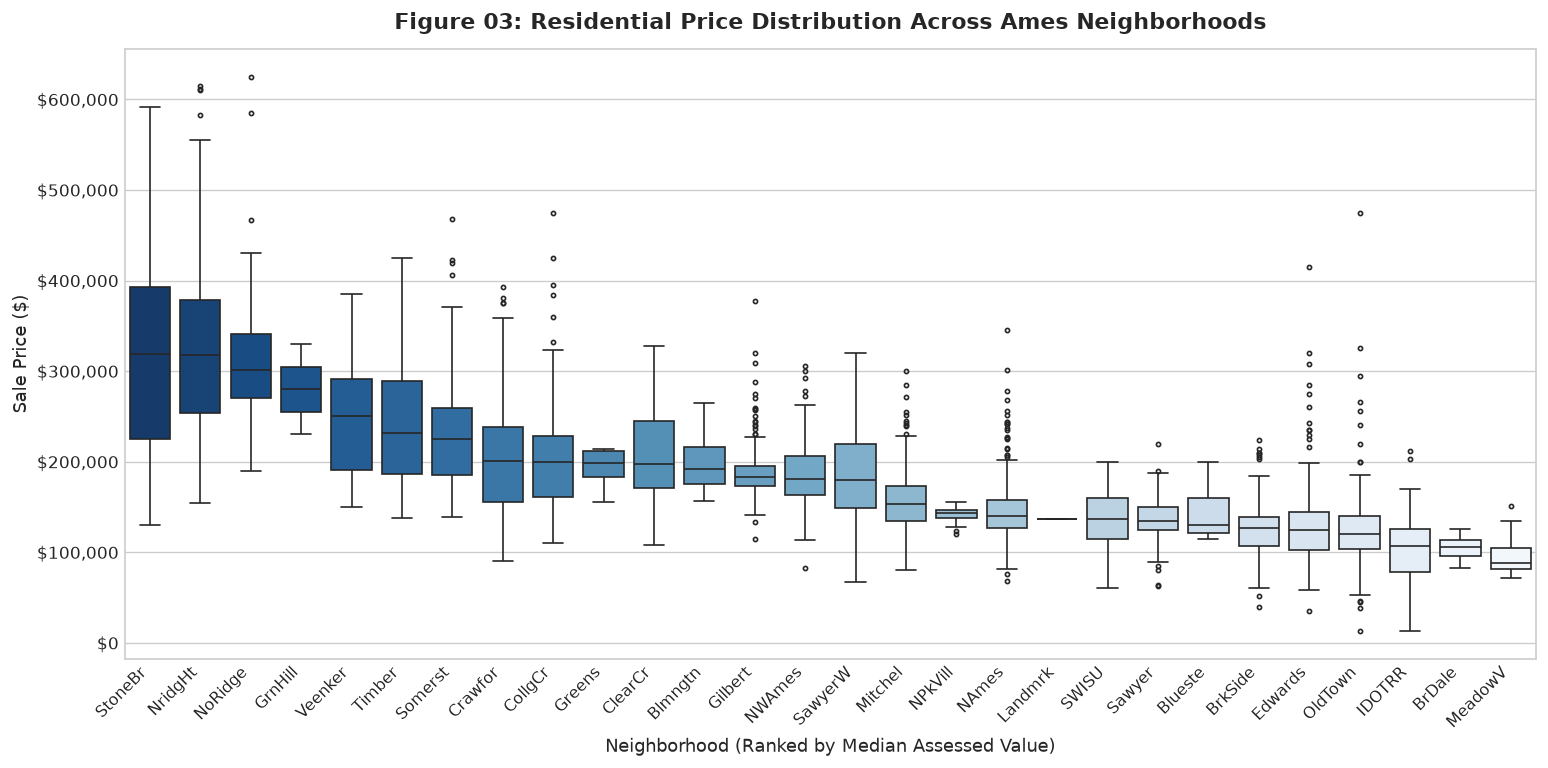

In [7]:
sorted_neigh = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=sorted_neigh, palette="Blues_r", ax=ax, fliersize=2.5)
ax.set_title("Figure 03: Residential Price Distribution Across Ames Neighborhoods", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Neighborhood (Ranked by Median Assessed Value)", fontsize=10.5)
ax.set_ylabel("Sale Price ($)", fontsize=10.5)
ax.yaxis.set_major_formatter("${x:,.0f}")
plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.tight_layout()
plt.show()

## Model Training

In [8]:
X_train, X_test, y_train_log, y_test_log, y_train_act, y_test_act = train_test_split(
    X_feat, y_log, y_actual, test_size=0.20, random_state=42
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Ridge Regression": Ridge(alpha=15.0, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=16, min_samples_split=4, random_state=42, n_jobs=-1),
    "XGBoost Regressor": xgb.XGBRegressor(
        n_estimators=600, learning_rate=0.035, max_depth=5, subsample=0.8,
        colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.2, random_state=42, n_jobs=-1
    )
}

pipelines = {}
benchmark_rows = []
test_preds = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    cv_neg_mse = cross_val_score(pipe, X_train, y_train_log, scoring="neg_mean_squared_error", cv=kf)
    cv_r2 = cross_val_score(pipe, X_train, y_train_log, scoring="r2", cv=kf)
    
    pipe.fit(X_train, y_train_log)
    pipelines[name] = pipe
    
    pred_log = pipe.predict(X_test)
    pred_act = np.expm1(pred_log)
    test_preds[name] = pred_act
    
    test_r2 = r2_score(y_test_act, pred_act)
    test_rmse = np.sqrt(mean_squared_error(y_test_act, pred_act))
    test_mae = mean_absolute_error(y_test_act, pred_act)
    
    benchmark_rows.append({
        "Model": name,
        "CV RMSE (log)": round(np.sqrt(-cv_neg_mse).mean(), 4),
        "CV R²": round(cv_r2.mean(), 4),
        "Test R²": round(test_r2, 4),
        "Test RMSE ($)": f"${test_rmse:,.0f}",
        "Test MAE ($)": f"${test_mae:,.0f}"
    })

benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df)

,Model,CV RMSE (log),CV R²,Test R²,Test RMSE ($),Test MAE ($)
0,Ridge Regression,0.1207,0.9103,0.9592,"$17,026","$11,554"
1,Random Forest,0.1338,0.8898,0.9335,"$21,740","$13,863"
2,XGBoost Regressor,0.1213,0.9094,0.9506,"$18,738","$12,025"


## Model Evaluation

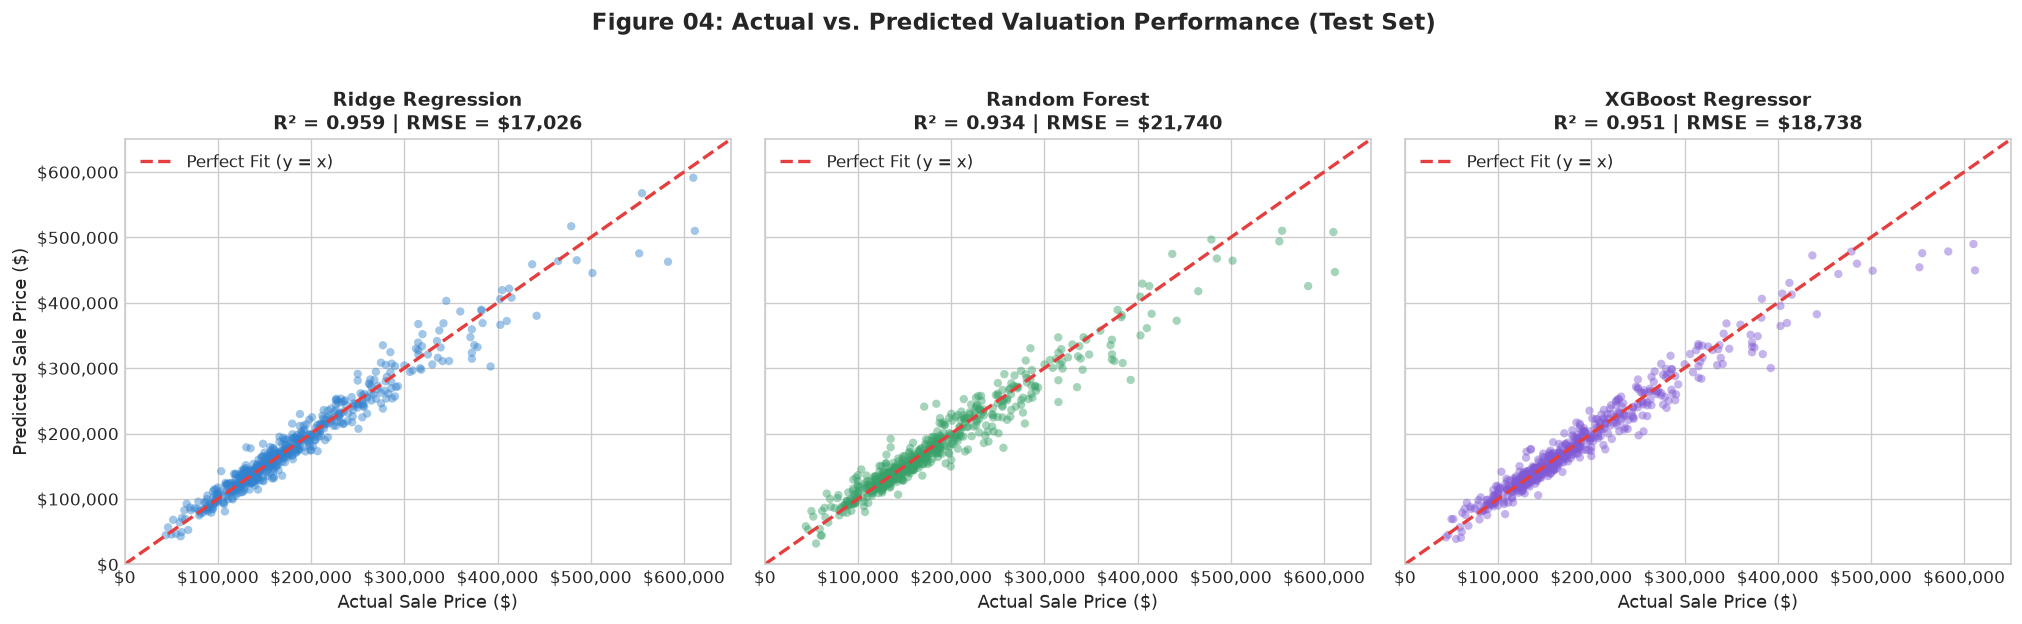

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0), sharey=True)
colors = ["#3182ce", "#38a169", "#805ad5"]

for idx, (name, col_hex) in enumerate(zip(models.keys(), colors)):
    ax = axes[idx]
    preds = test_preds[name]
    ax.scatter(y_test_act, preds, alpha=0.45, color=col_hex, s=25, edgecolors="none")
    ax.plot([0, 650000], [0, 650000], "--", color="#e53e3e", lw=2, label="Perfect Fit (y = x)")
    r2_val = r2_score(y_test_act, preds)
    rmse_val = np.sqrt(mean_squared_error(y_test_act, preds))
    ax.set_title(f"{name}\nR² = {r2_val:.3f} | RMSE = ${rmse_val:,.0f}", fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Actual Sale Price ($)", fontsize=10.5)
    if idx == 0:
        ax.set_ylabel("Predicted Sale Price ($)", fontsize=10.5)
    ax.xaxis.set_major_formatter("${x:,.0f}")
    ax.yaxis.set_major_formatter("${x:,.0f}")
    ax.set_xlim(0, 650000)
    ax.set_ylim(0, 650000)
    ax.legend(loc="upper left")

plt.suptitle("Figure 04: Actual vs. Predicted Valuation Performance (Test Set)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

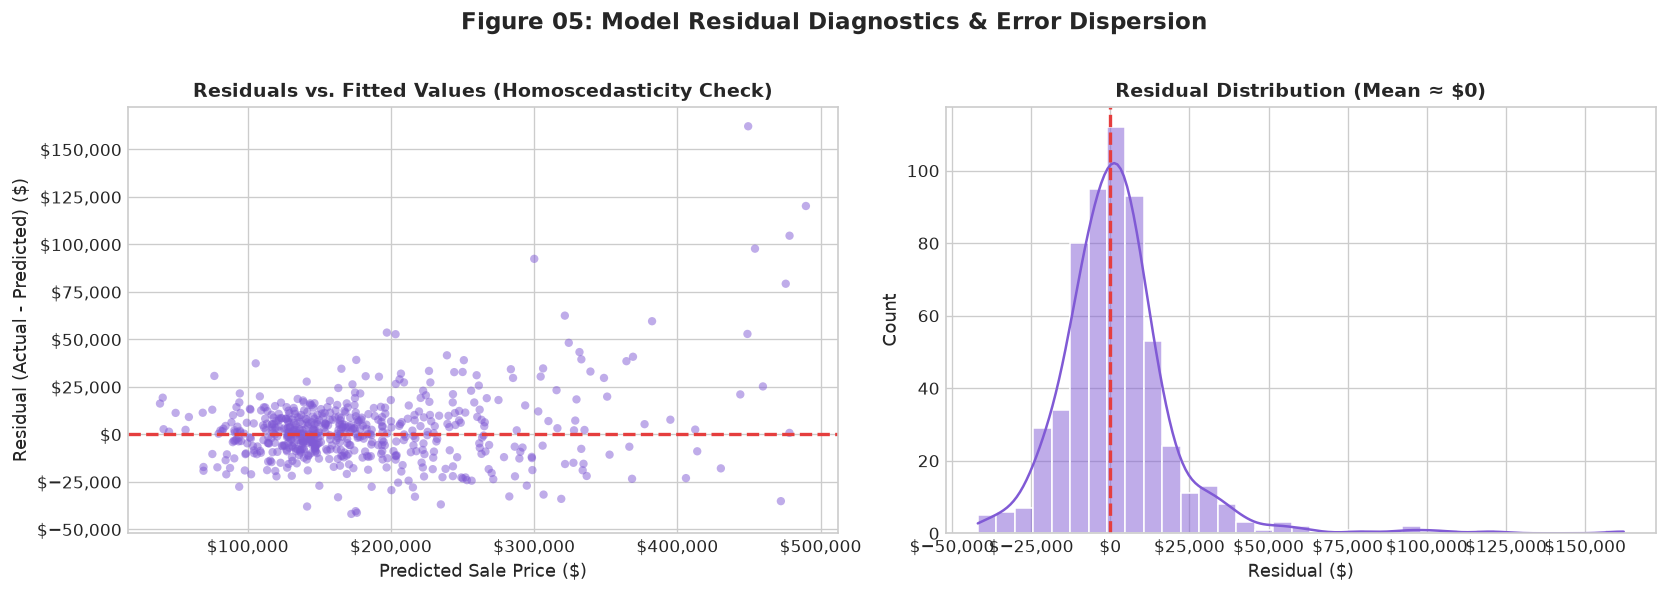

In [10]:
xgb_preds = test_preds["XGBoost Regressor"]
residuals = y_test_act - xgb_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(xgb_preds, residuals, alpha=0.5, color="#805ad5", s=25, edgecolors="none")
axes[0].axhline(0, color="#e53e3e", linestyle="--", lw=2)
axes[0].set_title("Residuals vs. Fitted Values (Homoscedasticity Check)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Predicted Sale Price ($)", fontsize=10.5)
axes[0].set_ylabel("Residual (Actual - Predicted) ($)", fontsize=10.5)
axes[0].xaxis.set_major_formatter("${x:,.0f}")
axes[0].yaxis.set_major_formatter("${x:,.0f}")

sns.histplot(residuals, kde=True, ax=axes[1], color="#805ad5", edgecolor="white", bins=35)
axes[1].axvline(0, color="#e53e3e", linestyle="--", lw=2)
axes[1].set_title("Residual Distribution (Mean ≈ $0)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Residual ($)", fontsize=10.5)
axes[1].set_ylabel("Count", fontsize=10.5)
axes[1].xaxis.set_major_formatter("${x:,.0f}")

plt.suptitle("Figure 05: Model Residual Diagnostics & Error Dispersion", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

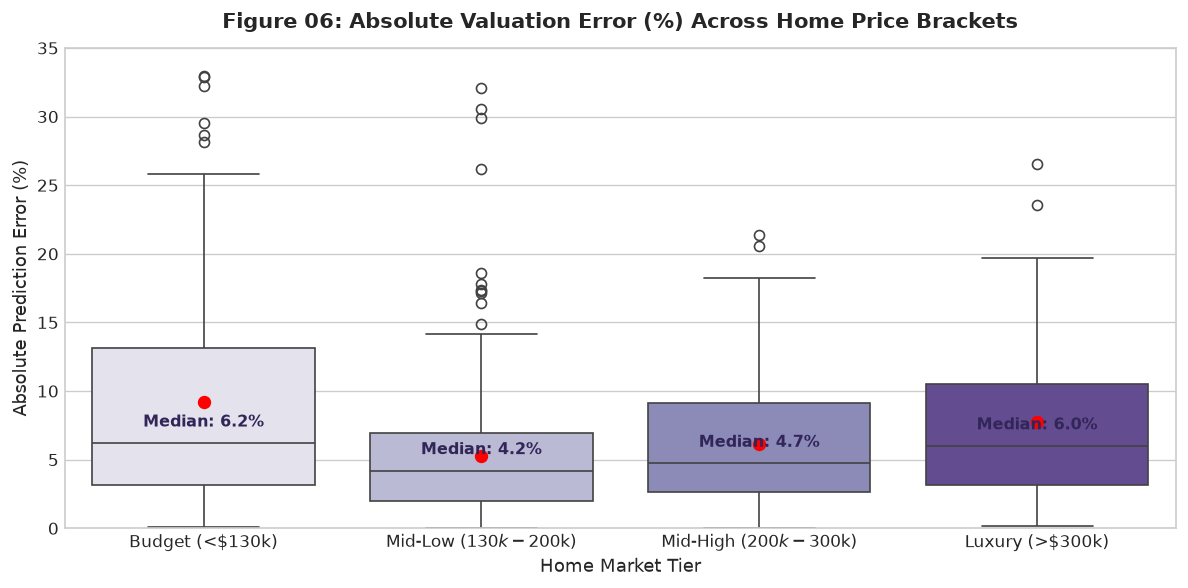

In [11]:
pct_errors = np.abs(residuals) / y_test_act * 100
bracket_df = pd.DataFrame({"ActualPrice": y_test_act, "AbsPctError": pct_errors})
bracket_bins = [0, 130000, 200000, 300000, 700000]
bracket_labels = ["Budget (<$130k)", "Mid-Low ($130k-$200k)", "Mid-High ($200k-$300k)", "Luxury (>$300k)"]
bracket_df["Bracket"] = pd.cut(bracket_df["ActualPrice"], bins=bracket_bins, labels=bracket_labels)

fig, ax = plt.subplots(figsize=(10, 5.0))
sns.boxplot(data=bracket_df, x="Bracket", y="AbsPctError", palette="Purples", ax=ax, showmeans=True,
            meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": "7"})
ax.set_title("Figure 06: Absolute Valuation Error (%) Across Home Price Brackets", fontsize=12.5, fontweight="bold", pad=12)
ax.set_xlabel("Home Market Tier", fontsize=10.5)
ax.set_ylabel("Absolute Prediction Error (%)", fontsize=10.5)
ax.set_ylim(0, 35)

medians = bracket_df.groupby("Bracket")["AbsPctError"].median()
for i, med in enumerate(medians):
    ax.text(i, med + 1.2, f"Median: {med:.1f}%", horizontalalignment="center", fontweight="bold", color="#322659", fontsize=9.5)

plt.tight_layout()
plt.show()

## Feature Importance

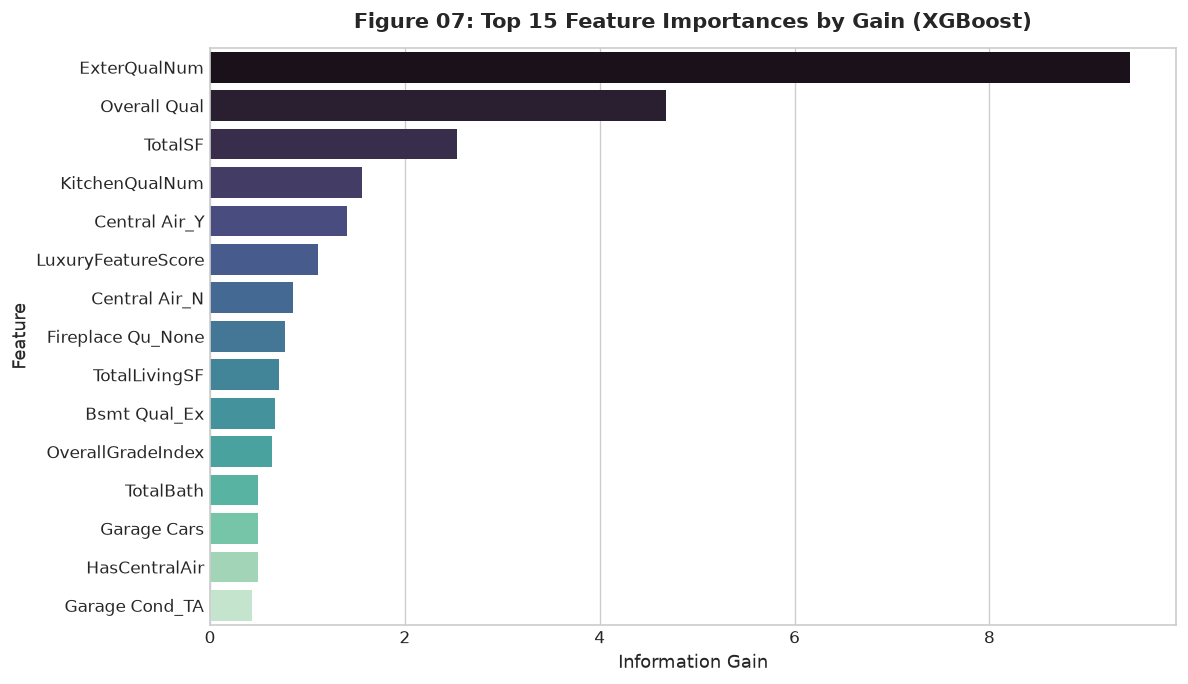

In [12]:
fitted_preprocessor = pipelines["XGBoost Regressor"].named_steps["preprocessor"]
fitted_xgb = pipelines["XGBoost Regressor"].named_steps["model"]

raw_feature_names = fitted_preprocessor.get_feature_names_out()
clean_feature_names = [f.replace("num__", "").replace("cat__", "") for f in raw_feature_names]

X_test_proc = fitted_preprocessor.transform(X_test)
X_test_proc_df = pd.DataFrame(X_test_proc, columns=clean_feature_names)

importance_gain = fitted_xgb.get_booster().get_score(importance_type="gain")
feature_map = {f"f{i}": clean_feature_names[i] for i in range(len(clean_feature_names))}
gain_named = {feature_map.get(k, k): v for k, v in importance_gain.items()}
imp_series = pd.Series(gain_named).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5.8))
sns.barplot(x=imp_series.values, y=imp_series.index, palette="mako", ax=ax)
ax.set_title("Figure 07: Top 15 Feature Importances by Gain (XGBoost)", fontsize=12.5, fontweight="bold", pad=12)
ax.set_xlabel("Information Gain", fontsize=10.5)
ax.set_ylabel("Feature", fontsize=10.5)
plt.tight_layout()
plt.show()

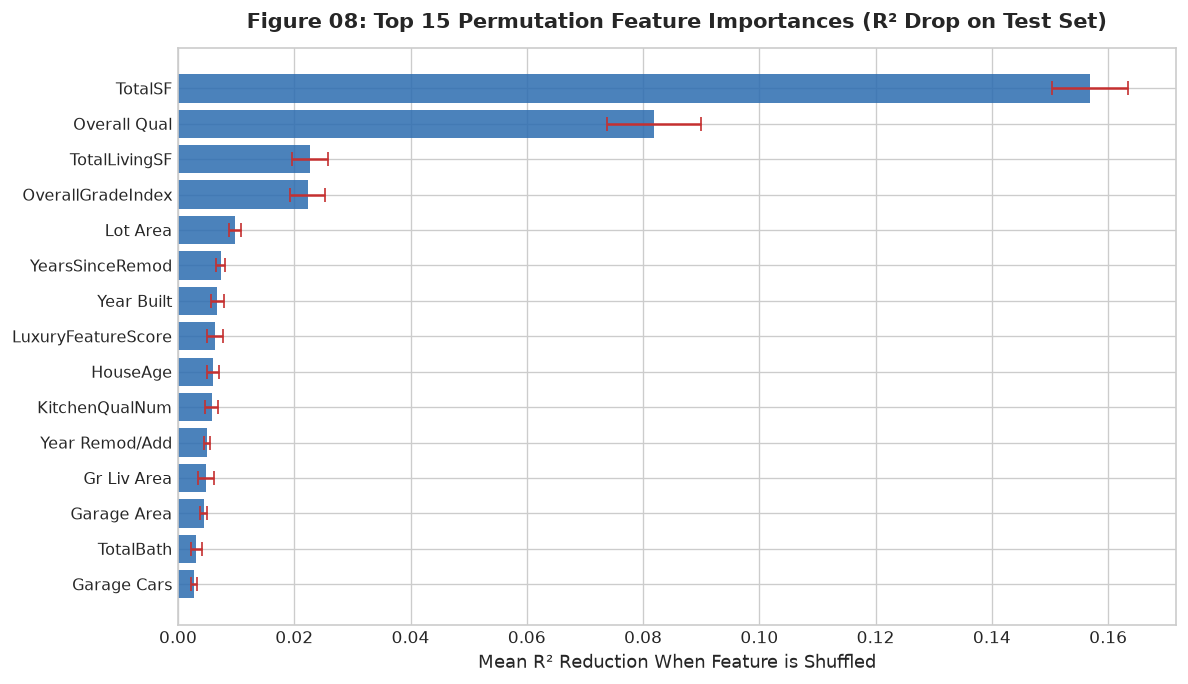

In [13]:
perm_imp = permutation_importance(fitted_xgb, X_test_proc, y_test_log, n_repeats=10, random_state=42, n_jobs=-1)
sorted_importances_idx = perm_imp.importances_mean.argsort()[::-1][:15]
top_perm_names = [clean_feature_names[i] for i in sorted_importances_idx]
top_perm_means = perm_imp.importances_mean[sorted_importances_idx]
top_perm_stds = perm_imp.importances_std[sorted_importances_idx]

fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(range(len(top_perm_names)), top_perm_means, xerr=top_perm_stds, align="center", color="#2b6cb0", alpha=0.85, ecolor="#c53030", capsize=4)
ax.set_yticks(range(len(top_perm_names)))
ax.set_yticklabels(top_perm_names, fontsize=9.5)
ax.invert_yaxis()
ax.set_title("Figure 08: Top 15 Permutation Feature Importances (R² Drop on Test Set)", fontsize=12.5, fontweight="bold", pad=12)
ax.set_xlabel("Mean R² Reduction When Feature is Shuffled", fontsize=10.5)
plt.tight_layout()
plt.show()

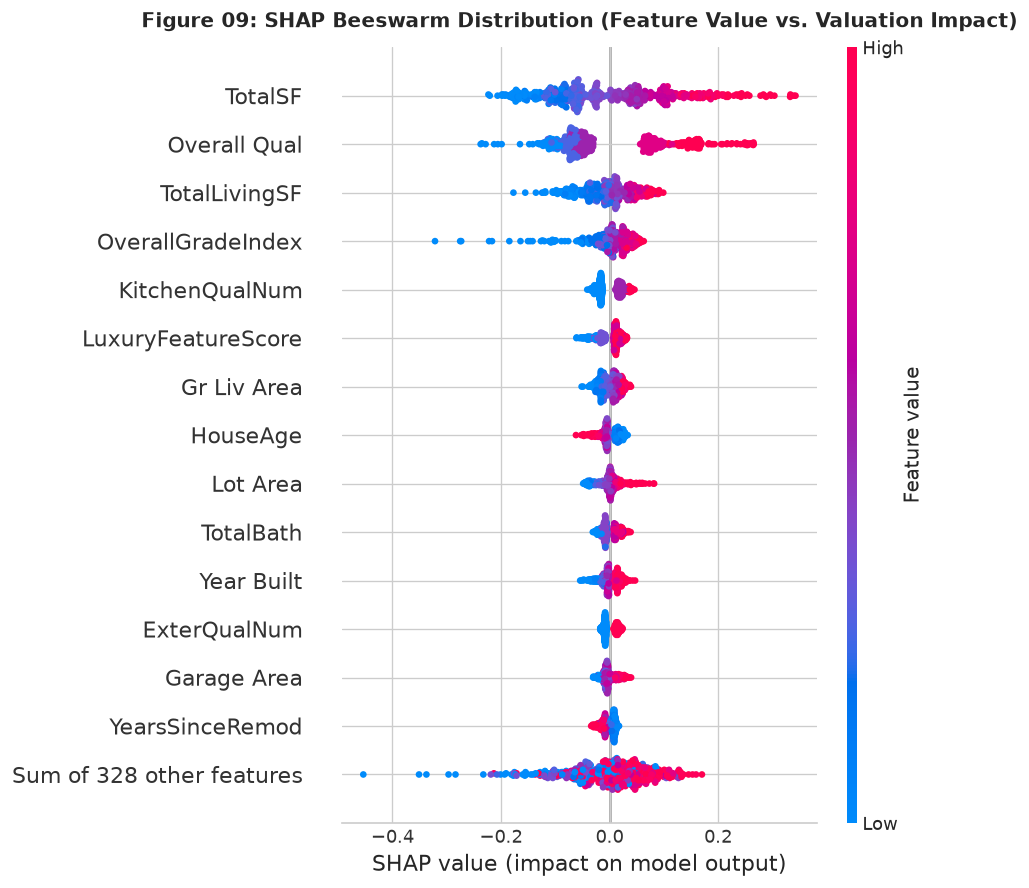

In [14]:
explainer = shap.TreeExplainer(fitted_xgb)
shap_values = explainer(X_test_proc_df)

fig = plt.figure(figsize=(10, 5.8))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("Figure 09: SHAP Beeswarm Distribution (Feature Value vs. Valuation Impact)", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

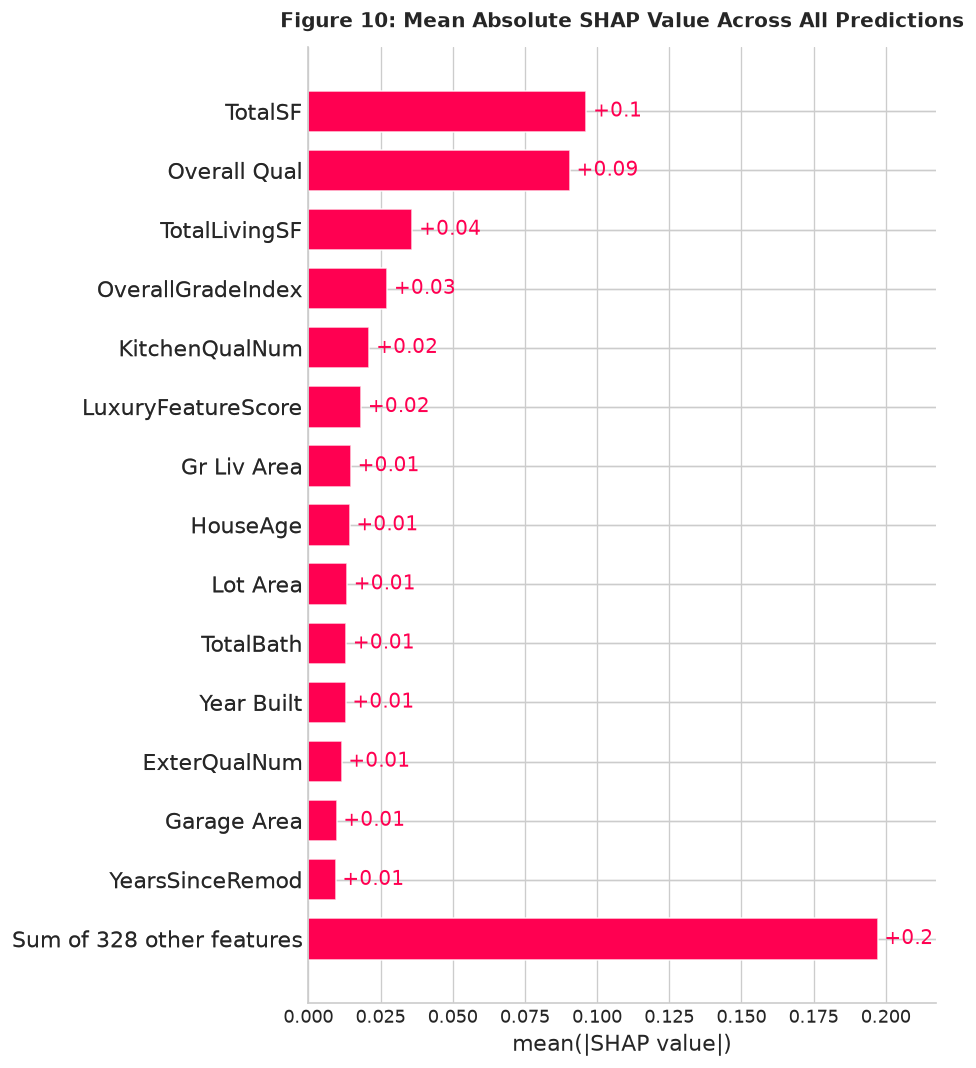

In [15]:
fig = plt.figure(figsize=(10, 5.5))
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Figure 10: Mean Absolute SHAP Value Across All Predictions", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

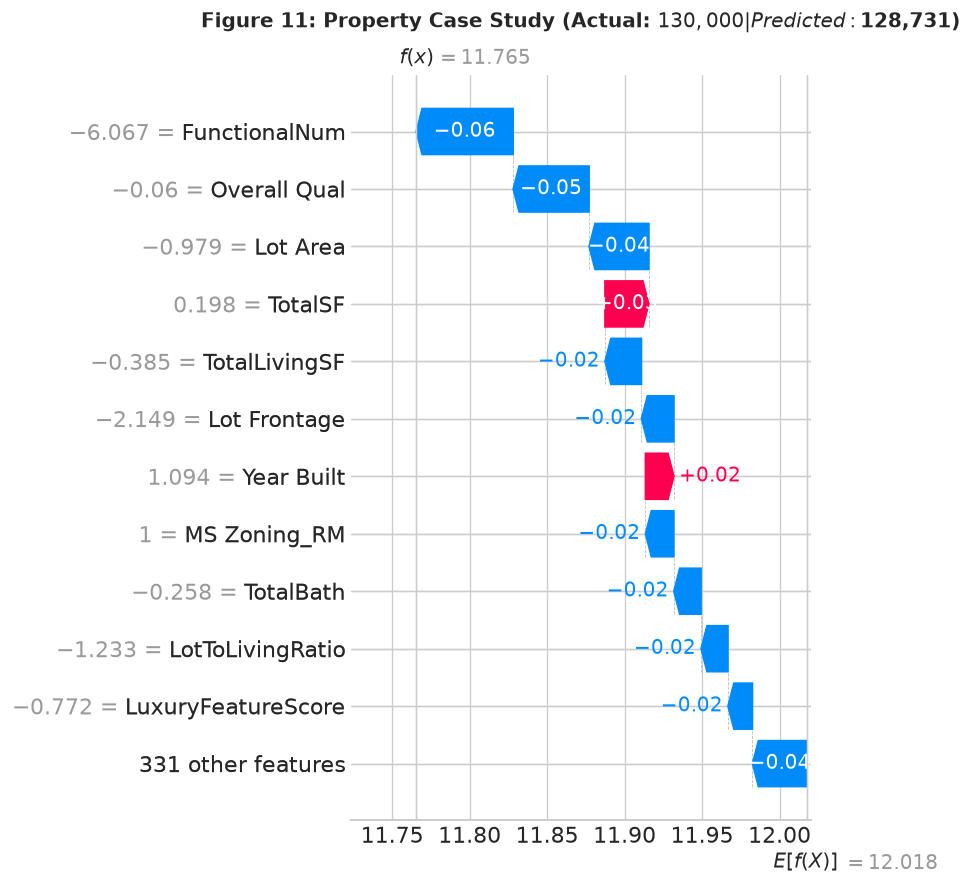

In [16]:
sample_idx = 42
fig = plt.figure(figsize=(10, 6.0))
shap.plots.waterfall(shap_values[sample_idx], max_display=12, show=False)
actual_p = y_test_act.iloc[sample_idx]
pred_p = test_preds["XGBoost Regressor"][sample_idx]
plt.title(f"Figure 11: Property Case Study (Actual: ${actual_p:,.0f} | Predicted: ${pred_p:,.0f})", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

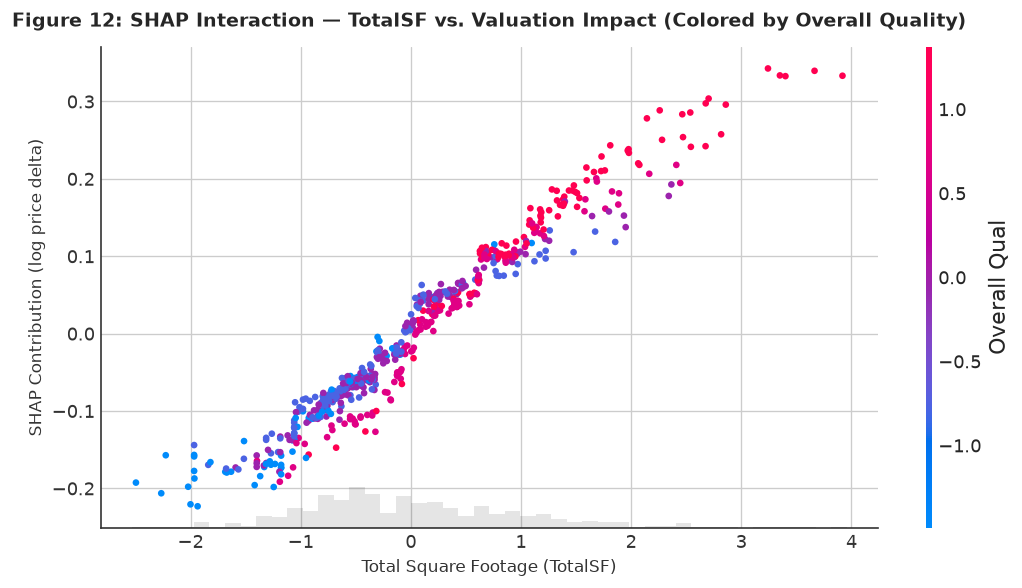

In [17]:
fig, ax = plt.subplots(figsize=(9, 5.0))
shap.plots.scatter(shap_values[:, "TotalSF"], color=shap_values[:, "Overall Qual"], ax=ax, show=False)
ax.set_title("Figure 12: SHAP Interaction — TotalSF vs. Valuation Impact (Colored by Overall Quality)", fontsize=11.5, fontweight="bold", pad=12)
ax.set_xlabel("Total Square Footage (TotalSF)", fontsize=10)
ax.set_ylabel("SHAP Contribution (log price delta)", fontsize=10)
plt.tight_layout()
plt.show()